# Build sum-of-products vibrational KEO for formaldehyde ($\mathrm{H_2CO}$) in valence coordinates using truncated N-mode representations

In [1]:
import jax
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from jax import numpy as jnp
from matplotlib.lines import Line2D
from scipy import constants, optimize

from etc.potentials import h2co_Ahmed
from gvib import Gvib
from keo_jax import batch_Gmat, com
from revad import dihedral, dot, norm

sns.set_theme(style="ticks", context="paper", font_scale=1.5)
plt.rcParams["figure.dpi"] = 300
plt.rcParams.update({"text.usetex": True, "font.family": "serif", "font.size": 14})

jax.config.update("jax_enable_x64", True)

G_to_invcm = (
    constants.value("Planck constant")
    * constants.value("Avogadro constant")
    * 1e16
    / (4.0 * np.pi**2 * constants.value("speed of light in vacuum"))
    * 1e5
)

In [2]:
def dtau_coo(coords):
    rCO, rCH1, rCH2, aOCH1, aOCH2, dtau = coords
    tau = jnp.pi + dtau
    return jnp.array([rCO, rCH1, rCH2, aOCH1, aOCH2, tau])


poten = jax.vmap(lambda x: h2co_Ahmed.poten(dtau_coo(x)), in_axes=0)
poten_serial = jax.jit(lambda x: poten(jnp.array([x]))[0])

vmin = optimize.minimize(
    poten_serial,
    x0=[1.0, 1.0, 1.0, 120.0 * np.pi / 180.0, 120.0 * np.pi / 180.0, 0.0],
)
r0 = vmin.x
v0 = vmin.fun
print("Equilibrium internal coordinates:\n", r0)
print("Min of the potential:", v0)

r0_ = np.copy(r0)
r0_[-1] -= 1e-3
hess = jax.hessian(poten_serial)(r0_)
ihess = jnp.linalg.pinv(hess)
ihess_diag = jnp.diag(ihess)
dE = 10000.0
r = jnp.sqrt(2 * dE * ihess_diag)
rmin = r0 - r
rmax = r0 + r
print("rmin:", rmin)
print("rmax:", rmax)


grids = np.concatenate((np.linspace(rmin, rmax, 5, axis=-1), r0[:, None]), axis=-1)

Equilibrium internal coordinates:
 [ 1.20337419e+00  1.10377465e+00  1.10377465e+00  2.12658330e+00
  2.12658330e+00 -6.95811962e-09]
Min of the potential: 3.0519799678090343e-11
rmin: [ 1.02585241  0.8163811   0.8163811   1.52348308  1.52348308 -1.22906636]
rmax: [1.38089598 1.39116819 1.39116819 2.72968352 2.72968352 1.22906635]


Define the internal-to-Cartesian and Cartesian-to-internal coordinate transformations for $\mathrm{H_2CO}$.

The internal coordinates are defined as:

1. $r_{\mathrm{CO}}$ — C–O bond length,
2. $r_{\mathrm{CH_1}}$ — C–H1 bond length,
3. $r_{\mathrm{CH_2}}$ — C–H2 bond length,
4. $\alpha_{\mathrm{H_1CO}}$ — H1–C–O bond angle,
5. $\alpha_{\mathrm{H_2CO}}$ — H2–C–O bond angle,
6. $\Delta\tau = \tau + \pi$, where $\tau$ is the book angle (dihedral angle) between the (H1CO) and (H2CO) planes.

The atom ordering in Cartesian coordinates is:

$$
\mathrm{C},\ \mathrm{O},\ \mathrm{H_1},\ \mathrm{H_2}
$$

In [3]:
masses = np.array([12.0, 15.99491463, 1.00782505, 1.00782505])  # masses of C, O, H, H

ncoo = 6


def internal_to_cartesian(q):
    rCO, rCH1, rCH2, aOCH1, aOCH2, dtau = q
    tau = np.pi + dtau
    xyz = [
        [0.0, 0.0, 0.0],
        [0.0, 0.0, rCO],
        [
            rCH1 * np.sin(aOCH1) * np.cos(tau * 0.5),
            -rCH1 * np.sin(aOCH1) * np.sin(tau * 0.5),
            rCH1 * np.cos(aOCH1),
        ],
        [
            rCH2 * np.sin(aOCH2) * np.cos(tau * 0.5),
            rCH2 * np.sin(aOCH2) * np.sin(tau * 0.5),
            rCH2 * np.cos(aOCH2),
        ],
    ]
    return np.array(xyz, dtype=object)


def cartesian_to_internal(xyz):
    C, O, H1, H2 = xyz

    CO = O - C
    CH1 = H1 - C
    CH2 = H2 - C

    rCO = norm(CO)
    rCH1 = norm(CH1)
    rCH2 = norm(CH2)

    aOCH1 = np.arccos(dot(CO, CH1) / (rCO * rCH1))
    aOCH2 = np.arccos(dot(CO, CH2) / (rCO * rCH2))

    tau = dihedral(H1, C, O, H2)
    dtau = tau + np.pi

    return np.array(
        [rCO, rCH1, rCH2, aOCH1, aOCH2, dtau],
        dtype=object,
    )

In [14]:
ref_indices = [grids.shape[-1] - 1] * ncoo

gvib_sop = {}
grovib_sop = {}
grot_sop = {}

for N in range(1, 7):
    print(f"generate G-matrix truncated at N = {N}...")
    gvib = Gvib(
        grids,
        masses,
        internal_to_cartesian,
        cartesian_to_internal,
        nmode_order=N,
        nmode_ref_indices=ref_indices,
    )
    gvib_sop[N], grovib_sop[N], grot_sop[N] = gvib.run(return_rot=True)

generate G-matrix truncated at N = 1...
generate G-matrix truncated at N = 2...
generate G-matrix truncated at N = 3...
generate G-matrix truncated at N = 4...
generate G-matrix truncated at N = 5...
generate G-matrix truncated at N = 6...


Evaluate G-matrix numerically on the multidimensional grid formed by the Cartesian product of the one-dimensional grids used to construct the sum-of-products representation

In [15]:
def internal_to_cartesian_jax(q):
    rCO, rCH1, rCH2, aOCH1, aOCH2, dtau = q
    tau = jnp.pi + dtau
    xyz = [
        [0.0, 0.0, 0.0],
        [0.0, 0.0, rCO],
        [
            rCH1 * jnp.sin(aOCH1) * jnp.cos(tau * 0.5),
            -rCH1 * jnp.sin(aOCH1) * jnp.sin(tau * 0.5),
            rCH1 * jnp.cos(aOCH1),
        ],
        [
            rCH2 * jnp.sin(aOCH2) * jnp.cos(tau * 0.5),
            rCH2 * jnp.sin(aOCH2) * jnp.sin(tau * 0.5),
            rCH2 * jnp.cos(aOCH2),
        ],
    ]
    return jnp.array(xyz, dtype=jnp.float64)


grid_ndim = np.stack(np.meshgrid(*grids, indexing="ij"), axis=-1)
grid_ndim = grid_ndim.reshape(-1, len(grids))

gmat = batch_Gmat(grid_ndim, masses, internal_to_cartesian_jax)
gvib_ndim = np.array(gmat[:, :ncoo, :ncoo])
grovib_ndim = np.array(gmat[:, ncoo : ncoo + 3, :ncoo])
grot_ndim = np.array(gmat[:, ncoo : ncoo + 3, ncoo : ncoo + 3])

Calculate point-wise differences between the sum-of-products and numerical G-matrix

In [16]:
# number of multidimensional grid points
ngrid = grid_ndim.shape[0]

# map each multidimensional grid point to its 1D grid indices
grid_indices = np.indices([len(grid) for grid in grids]).reshape(len(grids), -1).T

# evaluate the sum-of-products G-matrix on the full direct-product grid
diff_gvib = {}
diff_grovib = {}
diff_grot = {}

for N in range(1, 7):
    gvib_sop_eval = np.zeros((ngrid, ncoo, ncoo), dtype=np.float64)
    grovib_sop_eval = np.zeros((ngrid, 3, ncoo), dtype=np.float64)
    grot_sop_eval = np.zeros((ngrid, 3, 3), dtype=np.float64)

    for ipoint, inds in enumerate(grid_indices):
        for i in range(ncoo):
            for j in range(ncoo):
                sop = gvib_sop[N][i, j]

                value = 0.0

                for iterm in range(sop.nterms):
                    term = 1.0

                    for k in range(ncoo):
                        term *= sop.terms[iterm][k][inds[k]]

                    value += term

                gvib_sop_eval[ipoint, i, j] = value * G_to_invcm

    for ipoint, inds in enumerate(grid_indices):
        for i in range(3):
            for j in range(ncoo):
                sop = grovib_sop[N][i, j]

                value = 0.0

                for iterm in range(sop.nterms):
                    term = 1.0

                    for k in range(ncoo):
                        term *= sop.terms[iterm][k][inds[k]]

                    value += term

                grovib_sop_eval[ipoint, i, j] = value * G_to_invcm

    for ipoint, inds in enumerate(grid_indices):
        for i in range(3):
            for j in range(3):
                sop = grot_sop[N][i, j]

                value = 0.0

                for iterm in range(sop.nterms):
                    term = 1.0

                    for k in range(ncoo):
                        term *= sop.terms[iterm][k][inds[k]]

                    value += term

                grot_sop_eval[ipoint, i, j] = value * G_to_invcm

    diff_gvib[N] = gvib_sop_eval - gvib_ndim
    diff_grovib[N] = grovib_sop_eval - grovib_ndim
    diff_grot[N] = grot_sop_eval - grot_ndim

In [24]:
# differences

print("--- Gvib ---")
for N in diff_gvib.keys():
    print("N:", N)
    print("Maximum absolute difference:", np.max(np.abs(diff_gvib[N])))
    print("Mean absolute difference:", np.mean(np.abs(diff_gvib[N])))
    print("RMS difference:", np.sqrt(np.mean(diff_gvib[N] ** 2)))

print("\n--- Grovib ---")
for N in diff_grovib.keys():
    print("N:", N)
    print("Maximum absolute difference:", np.max(np.abs(diff_grovib[N])))
    print("Mean absolute difference:", np.mean(np.abs(diff_grovib[N])))
    print("RMS difference:", np.sqrt(np.mean(diff_grovib[N] ** 2)))

print("\n--- Grot ---")
for N in diff_grot.keys():
    print("N:", N)
    print("Maximum absolute difference:", np.max(np.abs(diff_grot[N])))
    print("Mean absolute difference:", np.mean(np.abs(diff_grot[N])))
    print("RMS difference:", np.sqrt(np.mean(diff_grot[N] ** 2)))

--- Gvib ---
N: 1
Maximum absolute difference: 379.083199258931
Mean absolute difference: 1.0251144725115102
RMS difference: 6.660375522093104
N: 2
Maximum absolute difference: 38.44817773329214
Mean absolute difference: 0.12001547876442342
RMS difference: 0.7429605384862339
N: 3
Maximum absolute difference: 16.414802162082538
Mean absolute difference: 0.011852465352169531
RMS difference: 0.11102273052716422
N: 4
Maximum absolute difference: 1.4175162563991535
Mean absolute difference: 0.0004516887651497886
RMS difference: 0.00592571207386207
N: 5
Maximum absolute difference: 3.923945612882562e-09
Mean absolute difference: 5.138665918935661e-11
RMS difference: 2.626825465104837e-10
N: 6
Maximum absolute difference: 3.923945612882562e-09
Mean absolute difference: 5.138665918935661e-11
RMS difference: 2.626825465104837e-10

--- Grovib ---
N: 1
Maximum absolute difference: 93.62072204826475
Mean absolute difference: 0.8521564859138292
RMS difference: 4.425787544547083
N: 2
Maximum absolut

In [25]:
pot = np.array(poten(grid_ndim))

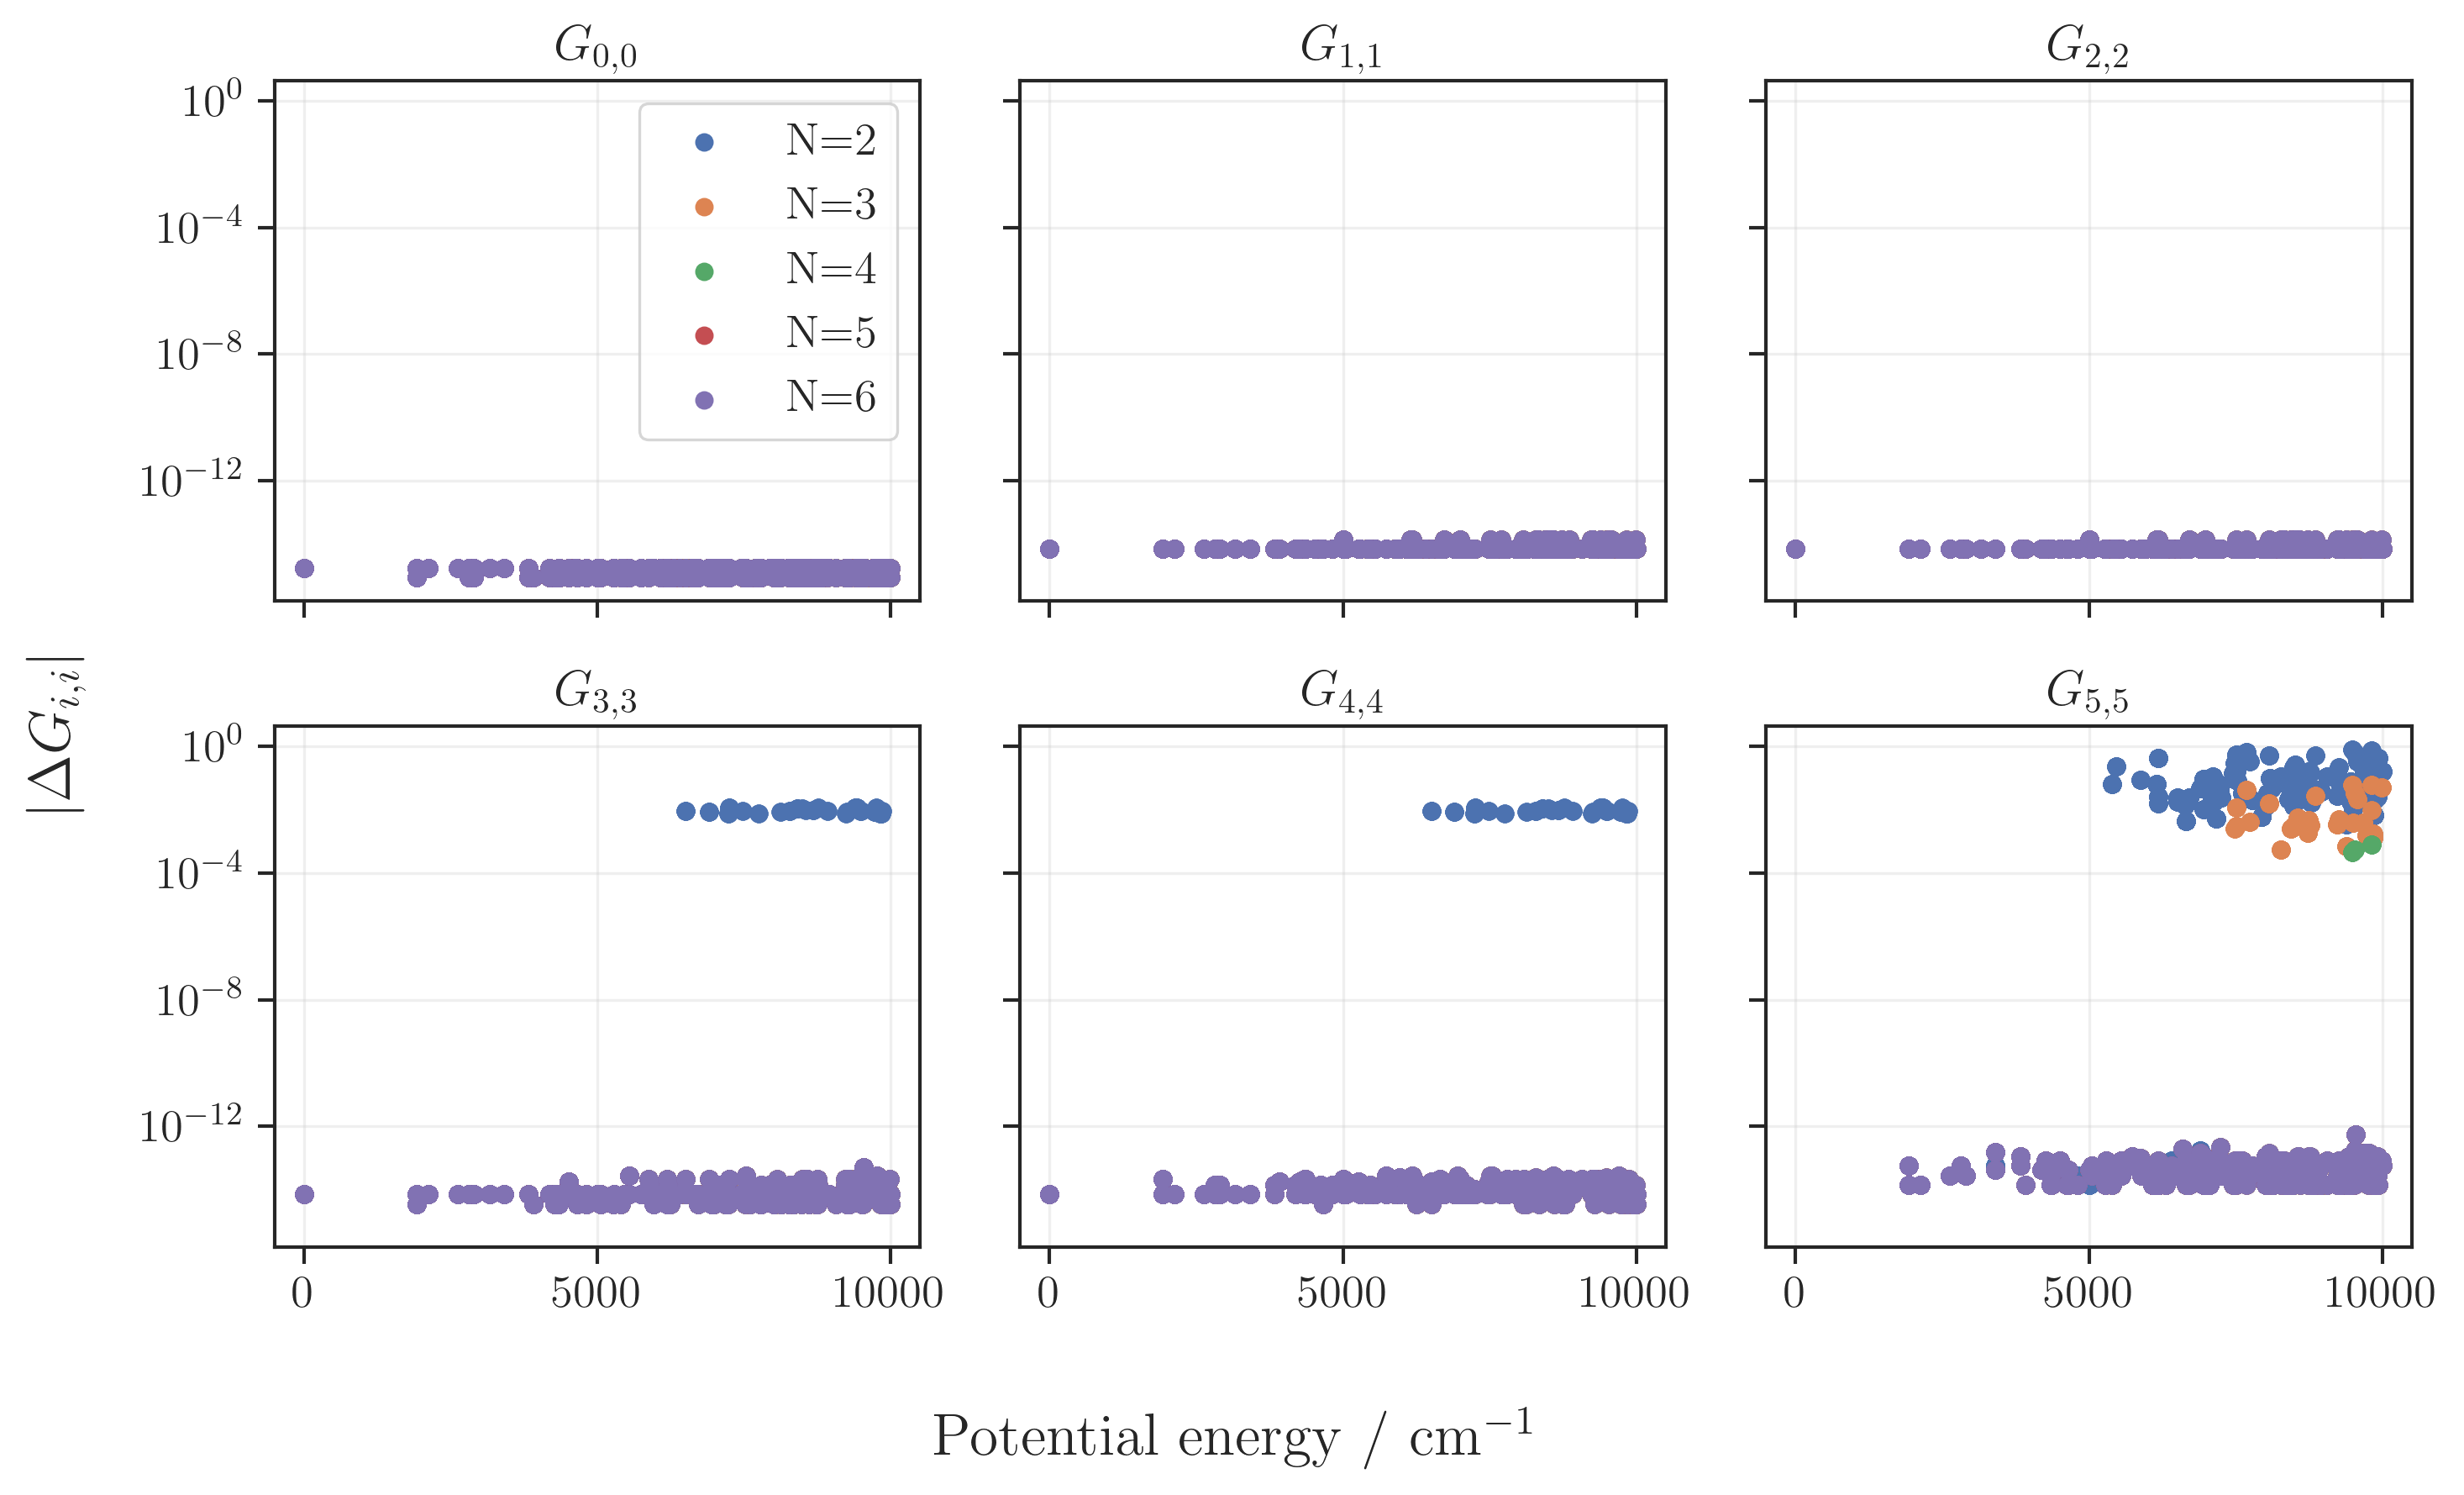

In [26]:
emax = 10000

pot[pot < 0] = None
pot[pot > emax] = None

fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex=True, sharey=True)
axes = axes.flatten()

for i in range(ncoo):
    ax = axes[i]

    for N in (2, 3, 4, 5, 6):
        ax.scatter(pot, np.abs(diff_gvib[N][:, i, i]), s=20, label=f"N={N}")
    ax.set_yscale("log")
    ax.set_title(rf"$G_{{{i},{i}}}$")
    ax.grid(alpha=0.3)

# Common axis labels
axes[0].legend()
fig.supxlabel("Potential energy / ${\\rm cm}^{-1}$")
fig.supylabel(r"$|\Delta G_{i,i}|$")

plt.tight_layout()
plt.show()

In [27]:
pot = np.array(poten(grid_ndim))
pot[pot < 0] = None

In [28]:
diff_gvib_diag = {key: np.diagonal(val, axis1=1, axis2=2) for key, val in diff_gvib.items()}

diff_gvib_odiag = {}
for key, val in diff_gvib.items():
    mask = ~np.eye(val.shape[1], dtype=bool)
    diff_gvib_odiag[key] = val[:, mask]

In [47]:
emax_list = np.linspace(1000, 20000, 30)

max_diff_gvib_diag = {N: [] for N in diff_gvib_diag.keys()}
mean_diff_gvib_diag = {N: [] for N in diff_gvib_diag.keys()}
rms_diff_gvib_diag = {N: [] for N in diff_gvib_diag.keys()}

max_diff_gvib_odiag = {N: [] for N in diff_gvib_diag.keys()}
mean_diff_gvib_odiag = {N: [] for N in diff_gvib_diag.keys()}
rms_diff_gvib_odiag = {N: [] for N in diff_gvib_diag.keys()}

max_diff_grot = {N: [] for N in diff_grot.keys()}
mean_diff_grot = {N: [] for N in diff_grot.keys()}
rms_diff_grot = {N: [] for N in diff_grot.keys()}

max_diff_grovib = {N: [] for N in diff_grovib.keys()}
mean_diff_grovib = {N: [] for N in diff_grovib.keys()}
rms_diff_grovib = {N: [] for N in diff_grovib.keys()}

for N in diff_gvib_diag.keys():
    for emax in emax_list:
        mask = pot < emax

        d = diff_gvib_diag[N][mask]
        max_diff_gvib_diag[N].append(np.max(np.abs(d)))
        mean_diff_gvib_diag[N].append(np.mean(np.abs(d)))
        rms_diff_gvib_diag[N].append(np.sqrt(np.mean(d**2)))

        d = diff_gvib_odiag[N][mask]
        max_diff_gvib_odiag[N].append(np.max(np.abs(d)))
        mean_diff_gvib_odiag[N].append(np.mean(np.abs(d)))
        rms_diff_gvib_odiag[N].append(np.sqrt(np.mean(d**2)))

        d = diff_grot[N][mask]
        max_diff_grot[N].append(np.max(np.abs(d)))
        mean_diff_grot[N].append(np.mean(np.abs(d)))
        rms_diff_grot[N].append(np.sqrt(np.mean(d**2)))

        d = diff_grovib[N][mask]
        max_diff_grovib[N].append(np.max(np.abs(d)))
        mean_diff_grovib[N].append(np.mean(np.abs(d)))
        rms_diff_grovib[N].append(np.sqrt(np.mean(d**2)))

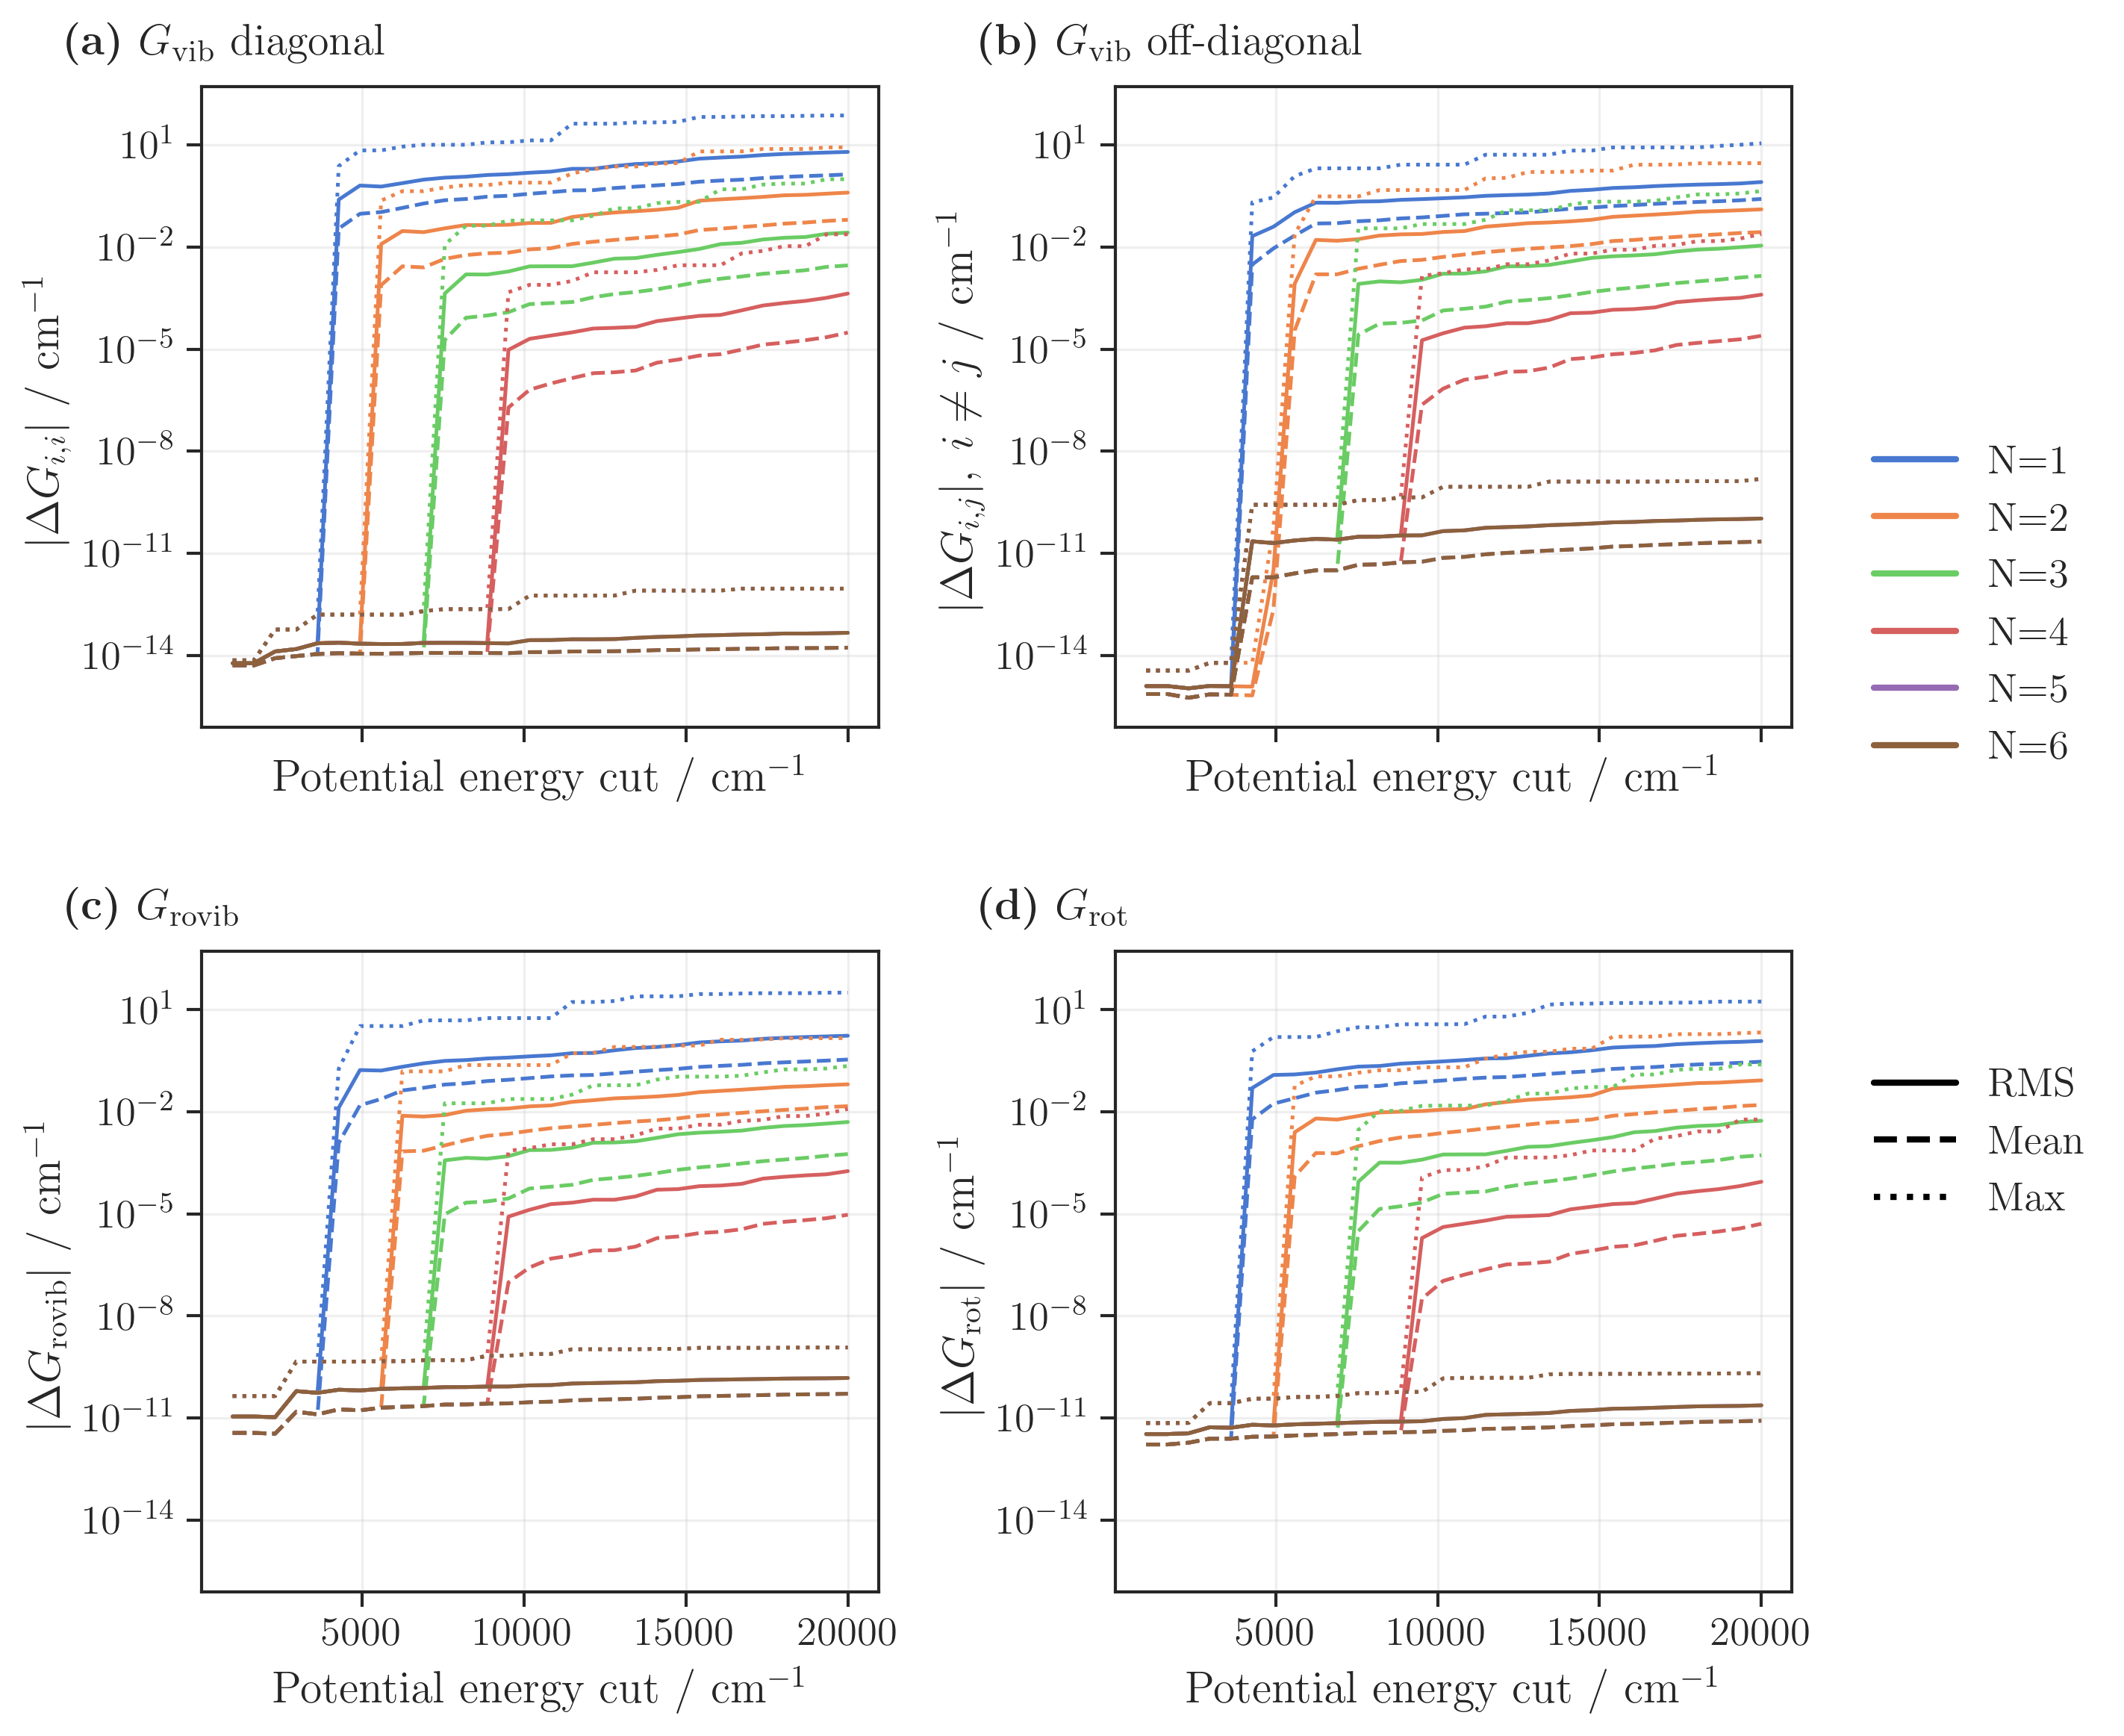

In [48]:
N_values = list(rms_diff_gvib_diag.keys())
colors = sns.color_palette("muted", n_colors=len(N_values))

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

ax1, ax2 = axes[0]
ax3, ax4 = axes[1]

# (a) G_vib diagonal
for N, col in zip(N_values, colors):
    ax1.plot(emax_list, rms_diff_gvib_diag[N], "-", color=col)
    ax1.plot(emax_list, mean_diff_gvib_diag[N], "--", color=col)
    ax1.plot(emax_list, max_diff_gvib_diag[N], ":", color=col)

ax1.set_ylabel(r"$|\Delta G_{i,i}|$ / ${\rm cm}^{-1}$")

# (b) G_vib off-diagonal
for N, col in zip(N_values, colors):
    ax2.plot(emax_list, rms_diff_gvib_odiag[N], "-", color=col)
    ax2.plot(emax_list, mean_diff_gvib_odiag[N], "--", color=col)
    ax2.plot(emax_list, max_diff_gvib_odiag[N], ":", color=col)

ax2.set_ylabel(r"$|\Delta G_{i,j}|,\; i\neq j$ / ${\rm cm}^{-1}$")

# (c) G_rovib
for N, col in zip(N_values, colors):
    ax3.plot(emax_list, rms_diff_grovib[N], "-", color=col)
    ax3.plot(emax_list, mean_diff_grovib[N], "--", color=col)
    ax3.plot(emax_list, max_diff_grovib[N], ":", color=col)

ax3.set_xlabel(r"Potential energy cut / ${\rm cm}^{-1}$")
ax3.set_ylabel(r"$|\Delta G_{\rm rovib}|$ / ${\rm cm}^{-1}$")

# (d) G_rot
for N, col in zip(N_values, colors):
    ax4.plot(emax_list, rms_diff_grot[N], "-", color=col)
    ax4.plot(emax_list, mean_diff_grot[N], "--", color=col)
    ax4.plot(emax_list, max_diff_grot[N], ":", color=col)

ax4.set_xlabel(r"Potential energy cut / ${\rm cm}^{-1}$")
ax4.set_ylabel(r"$|\Delta G_{\rm rot}|$ / ${\rm cm}^{-1}$")


for ax in axes.flat:
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    # show y tick labels on both columns
    ax.tick_params(axis="y", labelleft=True)

ax1.set_xlabel(r"Potential energy cut / ${\rm cm}^{-1}$")
ax2.set_xlabel(r"Potential energy cut / ${\rm cm}^{-1}$")


# panel labels
labels = [
    r"\textbf{(a)} $G_{\rm vib}$ diagonal",
    r"\textbf{(b)} $G_{\rm vib}$ off-diagonal",
    r"\textbf{(c)} $G_{\rm rovib}$",
    r"\textbf{(d)} $G_{\rm rot}$",
]

for ax, lab in zip(axes.flat, labels):
    ax.text(
        -0.20,
        1.10,
        lab,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        va="top",
    )


N_leg = [
    Line2D([0], [0], color=col, linestyle="-", linewidth=2, label=f"N={N}")
    for N, col in zip(N_values, colors)
]

fig.legend(handles=N_leg, loc="center left", bbox_to_anchor=(0.83, 0.65), frameon=False)


stat_leg = [
    Line2D([0], [0], color="black", linestyle="-", linewidth=2, label="RMS"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=2, label="Mean"),
    Line2D([0], [0], color="black", linestyle=":", linewidth=2, label="Max"),
]

fig.legend(
    handles=stat_leg, loc="center left", bbox_to_anchor=(0.83, 0.35), frameon=False
)

fig.subplots_adjust(
    left=0.10,
    right=0.81,  # reserve space for legends
    bottom=0.10,
    top=0.94,
    wspace=0.35,
    hspace=0.35,
)

fig.savefig("h2co_gmat_conv.pdf", bbox_inches="tight", dpi=300)
plt.show()